Alumna: Melissa Mallo.



Curso: Herramientas básicas para el Análisis de Datos.



Institución: UTN.



Trabajo: Final Integrador.

# PROYECTO FINAL: ANÁLISIS DE HÁBITOS DE ASISTENCIA EN GIMNASIOS

## Objetivo general

Analizar los patrones de asistencia de los usuarios de gimnasios para identificar variaciones según el día de la semana y el mes.

## Pregunta principal

¿Cómo se comportan los hábitos de asistencia de los usuarios de gimnasios y cómo varían según el día de la semana y el mes?

## Preguntas de investigación

1. ¿Qué proporción de los registros corresponde a asistencias y qué proporción a inasistencias?
2. ¿Qué días de la semana presentan mayores y menores niveles de asistencia?
3. ¿Qué meses presentan mayores y menores niveles de asistencia?

## Herramientas

Python, Pandas, Matplotlib, Seaborn, Power BI y GitHub.

## Descripción y justificación del dataset

Para este trabajo se seleccionó un conjunto de datos público del proyecto *Machine Learning & Habit Formation*, disponible en Open Science Framework (OSF).

La base original contiene 61.012.050 registros, 10 variables y 30.316 usuarios identificados mediante códigos numéricos.

Debido al tamaño del archivo original, se seleccionó una muestra aleatoria de 100.000 registros utilizando RStudio.

El dataset incluye información sobre fechas, asistencia, días de la semana, meses y variables relacionadas con la continuidad de los hábitos.

Se eligió porque permite analizar patrones de asistencia y comparar su comportamiento en distintos períodos.

El análisis se realizará con Python, utilizando Pandas, Matplotlib y Seaborn, y posteriormente se presentarán los resultados mediante un dashboard en Power BI.

**Limitación:** los resultados obtenidos describen la muestra seleccionada y no necesariamente representan a todos los usuarios de la base original.

In [ ]:
from google.colab import files
uploaded = files.upload()
import pandas as pd

df = pd.read_csv("muestra_gimnasios.csv")

df.head()

,short_p_id,date,attended,dow,month,streak,time_lag,streak_dow,folds,last7days_attendance
0,50250,2016-10-20,0,5,10,0,4.0,0,3,2
1,20106,2017-06-25,1,1,6,0,14.0,0,2,0
2,10174,2011-01-01,0,7,1,0,37.0,0,2,0
3,7672,2008-09-04,0,5,9,0,253.0,0,4,0
4,2116,2016-11-14,1,2,11,0,2.0,2,5,5


In [ ]:
# AUDITORIA INICIAL DE DATOS

print("DIMENSIONES:")
print(df.shape)

print("\nTIPOS DE DATOS:")
print(df.dtypes)

print("\nVALORES FALTANTES:")
print(df.isna().sum())

print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())

print("\nESTADISTICAS DESCRIPTIVAS:")
display(df.describe())

DIMENSIONES:
(100000, 10)

TIPOS DE DATOS:
short_p_id                int64
date                     object
attended                  int64
dow                       int64
month                     int64
streak                    int64
time_lag                float64
streak_dow                int64
folds                     int64
last7days_attendance      int64
dtype: object

VALORES FALTANTES:
short_p_id               0
date                     0
attended                 0
dow                      0
month                    0
streak                   0
time_lag                35
streak_dow               0
folds                    0
last7days_attendance     0
dtype: int64

REGISTROS DUPLICADOS:
0

ESTADISTICAS DESCRIPTIVAS:


,short_p_id,attended,dow,month,streak,time_lag,streak_dow,folds,last7days_attendance
count,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,99965.000000,100000.000000,100000.000000,100000.000000
mean,29611.701720,0.176490,3.99687,6.481470,0.41181,84.765488,0.514020,3.498230,1.225860
std,17092.359723,0.381238,1.99914,3.429503,2.17711,224.816259,2.179057,1.704619,1.655806
min,3.000000,0.000000,1.00000,1.000000,0.00000,1.000000,0.000000,1.000000,0.000000
25%,14835.000000,0.000000,2.00000,4.000000,0.00000,2.000000,0.000000,2.000000,0.000000
50%,29640.000000,0.000000,4.00000,6.000000,0.00000,9.000000,0.000000,4.000000,0.000000
75%,44464.000000,0.000000,6.00000,9.000000,0.00000,57.000000,0.000000,5.000000,2.000000
max,59194.000000,1.000000,7.00000,12.000000,172.00000,3489.000000,128.000000,6.000000,7.000000


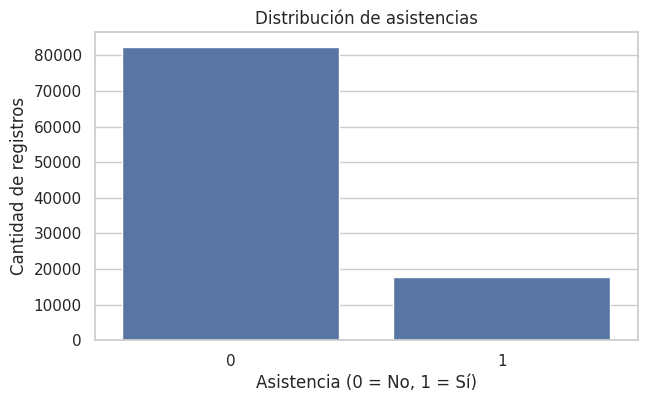

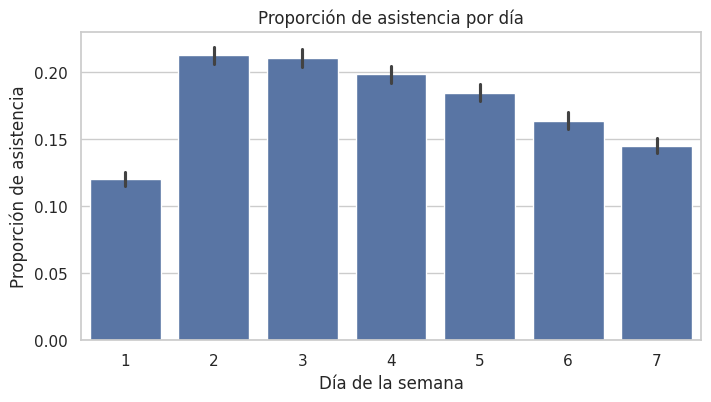

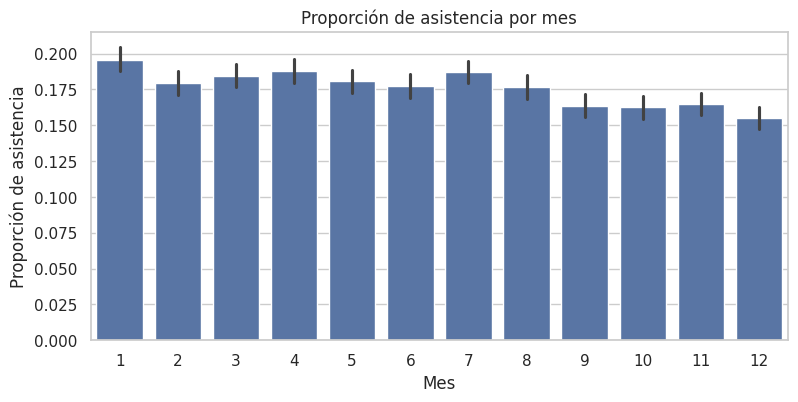

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribución de asistencias
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="attended")
plt.title("Distribución de asistencias")
plt.xlabel("Asistencia (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de registros")
plt.show()

# 2. Asistencia por día de la semana
plt.figure(figsize=(8,4))
sns.barplot(data=df, x="dow", y="attended")
plt.title("Proporción de asistencia por día")
plt.xlabel("Día de la semana")
plt.ylabel("Proporción de asistencia")
plt.show()

# 3. Asistencia por mes
plt.figure(figsize=(9,4))
sns.barplot(data=df, x="month", y="attended")
plt.title("Proporción de asistencia por mes")
plt.xlabel("Mes")
plt.ylabel("Proporción de asistencia")
plt.show()

In [ ]:
# INDICADORES PRINCIPALES

total_registros = len(df)
total_asistencias = df["attended"].sum()
porcentaje_asistencia = df["attended"].mean() * 100
total_usuarios = df["short_p_id"].nunique()

print("TOTAL DE REGISTROS:", total_registros)
print("TOTAL DE ASISTENCIAS:", total_asistencias)
print("PORCENTAJE DE ASISTENCIA:", round(porcentaje_asistencia, 2), "%")
print("USUARIOS EN LA MUESTRA:", total_usuarios)

TOTAL DE REGISTROS: 100000
TOTAL DE ASISTENCIAS: 17649
PORCENTAJE DE ASISTENCIA: 17.65 %
USUARIOS EN LA MUESTRA: 25164


In [ ]:
# PREPARACION PARA POWER BI

df["date"] = pd.to_datetime(df["date"])

df["anio"] = df["date"].dt.year
df["mes"] = df["date"].dt.month
df["dia_semana"] = df["date"].dt.day_name()

df.to_csv("gimnasios_powerbi.csv", index=False)

from google.colab import files
files.download("gimnasios_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# LIMPIEZA DE DATOS

df["date"] = pd.to_datetime(df["date"])

df_limpio = df.drop_duplicates().copy()

df_limpio = df_limpio.dropna(subset=["time_lag"])

print("Registros originales:", len(df))
print("Registros limpios:", len(df_limpio))
print("Valores faltantes:", df_limpio.isna().sum().sum())
print("Duplicados:", df_limpio.duplicated().sum())

Registros originales: 100000
Registros limpios: 99965
Valores faltantes: 0
Duplicados: 0


In [ ]:
# EXPORTAR BASE LIMPIA

df_limpio.to_csv("gimnasios_limpio.csv", index=False)

from google.colab import files
files.download("gimnasios_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# INDICADORES DE LA BASE LIMPIA

print("TOTAL DE REGISTROS:", len(df_limpio))

print("TOTAL DE USUARIOS:", df_limpio["short_p_id"].nunique())

print("TOTAL DE ASISTENCIAS:", df_limpio["attended"].sum())

print("PORCENTAJE DE ASISTENCIA:",
      round(df_limpio["attended"].mean() * 100, 2), "%")

print("\nASISTENCIA POR DÍA:")
print(df_limpio.groupby("dow")["attended"].mean().round(3))

print("\nASISTENCIA POR MES:")
print(df_limpio.groupby("month")["attended"].mean().round(3))

TOTAL DE REGISTROS: 99965
TOTAL DE USUARIOS: 25158
TOTAL DE ASISTENCIAS: 17614
PORCENTAJE DE ASISTENCIA: 17.62 %

ASISTENCIA POR DÍA:
dow
1    0.120
2    0.213
3    0.210
4    0.198
5    0.184
6    0.164
7    0.145
Name: attended, dtype: float64

ASISTENCIA POR MES:
month
1     0.195
2     0.179
3     0.185
4     0.187
5     0.180
6     0.177
7     0.187
8     0.176
9     0.164
10    0.162
11    0.165
12    0.155
Name: attended, dtype: float64


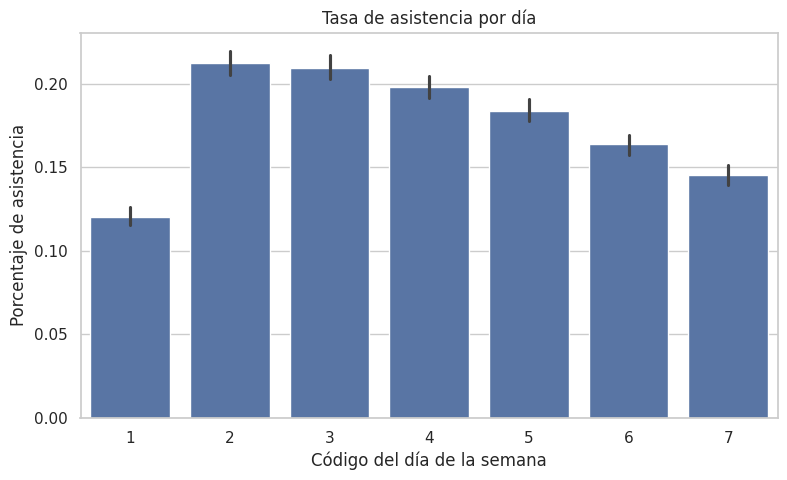

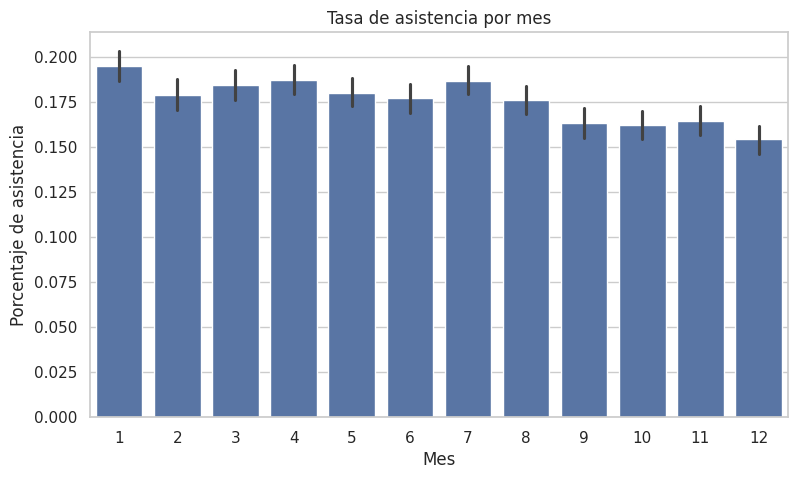

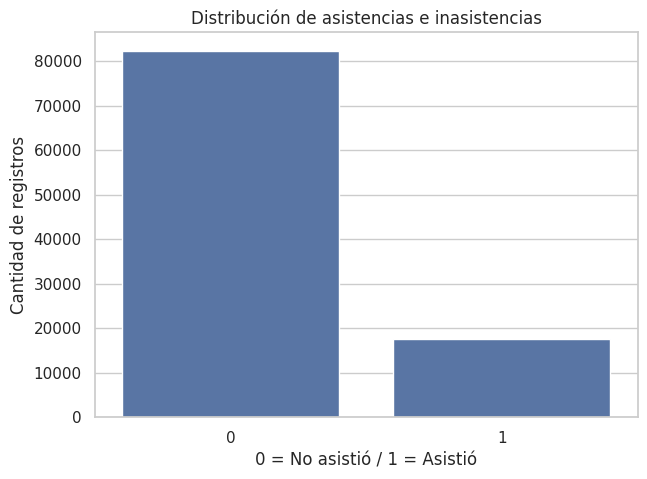

In [ ]:
# GRAFICOS DEFINITIVOS CON DATOS LIMPIOS

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Asistencia por día
plt.figure(figsize=(9,5))
sns.barplot(data=df_limpio, x="dow", y="attended")
plt.title("Tasa de asistencia por día")
plt.xlabel("Código del día de la semana")
plt.ylabel("Porcentaje de asistencia")
plt.show()

# Asistencia por mes
plt.figure(figsize=(9,5))
sns.barplot(data=df_limpio, x="month", y="attended")
plt.title("Tasa de asistencia por mes")
plt.xlabel("Mes")
plt.ylabel("Porcentaje de asistencia")
plt.show()

# Distribución de asistencias e inasistencias
plt.figure(figsize=(7,5))
sns.countplot(data=df_limpio, x="attended")
plt.title("Distribución de asistencias e inasistencias")
plt.xlabel("0 = No asistió / 1 = Asistió")
plt.ylabel("Cantidad de registros")
plt.show()

## Interpretación de los resultados

### 1. Distribución de asistencias e inasistencias

Se observa que la mayoría de los registros corresponden a inasistencias. El porcentaje de asistencia es del 17,62%, mientras que las inasistencias representan el 82,38% de los registros analizados.

### 2. Asistencia por día de la semana

Los días identificados con los códigos 2 y 3 presentan los mayores niveles de asistencia, con aproximadamente 21,3% y 21%, respectivamente. El día 1 presenta el menor porcentaje, con un 12%.

Esto evidencia diferencias en los hábitos de asistencia según el día de la semana.

### 3. Asistencia por mes

Enero presenta el mayor nivel de asistencia, con un 19,5%. En cambio, diciembre registra el menor porcentaje, con un 15,5%.

Se observa una tendencia general de disminución de la asistencia hacia los últimos meses del año.

## Conclusiones finales

A partir del análisis de los 99.965 registros de la muestra limpia, se identificó que el porcentaje general de asistencia es del 17,62%.

Los resultados muestran diferencias en los niveles de asistencia según el día de la semana. Los días 2 y 3 presentan los porcentajes más elevados, mientras que el día 1 registra el menor nivel.

En cuanto a la distribución mensual, enero presenta el mayor porcentaje de asistencia y diciembre el menor.

Estos resultados permiten observar patrones de comportamiento y variaciones en los hábitos de asistencia de los usuarios de gimnasios.

Como limitación, el análisis se realizó sobre una muestra aleatoria de 100.000 registros de una base original mucho más amplia, por lo que los resultados deben interpretarse dentro de ese contexto.